In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("health_study_dataset.csv")

In [20]:
df.info()
print(df.describe())
print(df.head(3))

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB
             id         age      height      weight  systolic_bp  cholesterol  \
count  800.0000  800.000000  800.000000  800.000000   800.000000   800.000000   
mean   400.5000   49.426250  171.849250   73.413000   149.178625     4.929150   
std    231.0844   14.501118    9.804259   13.685059    12.793360     0.848413   
min      1.0000   18.000000  144.400000   33.700000   106.8000

In [21]:
# Plockar ut nyckeltal ur olika kolumner och grupperar i ny dataframe:

def health_stats(df, cols):
    return df[cols].agg(['mean', 'median', 'min', 'max']).T

health_data = health_stats(df, ["age", "weight", "height", "systolic_bp", "cholesterol"])
print(health_data)


                   mean  median    min     max
age           49.426250   50.00   18.0   90.00
weight        73.413000   73.20   33.7  114.40
height       171.849250  171.35  144.4  200.40
systolic_bp  149.178625  149.40  106.8  185.90
cholesterol    4.929150    4.97    2.5    7.88


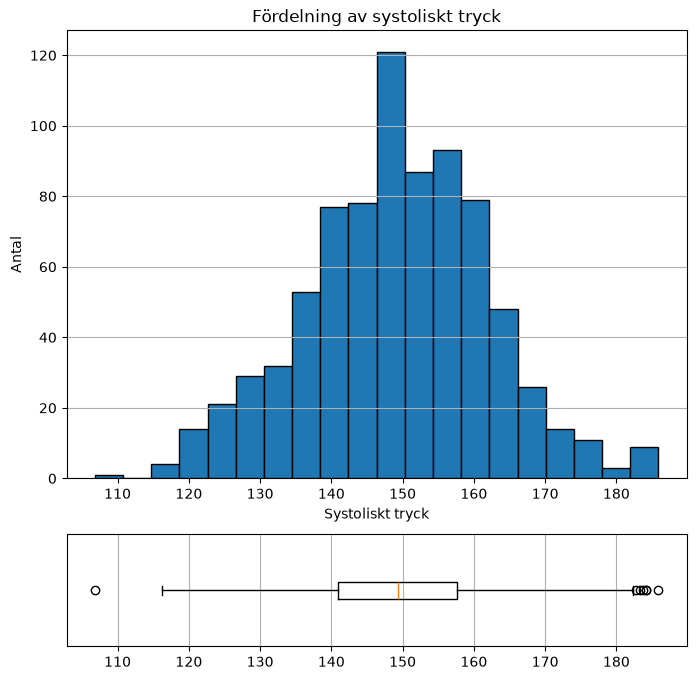

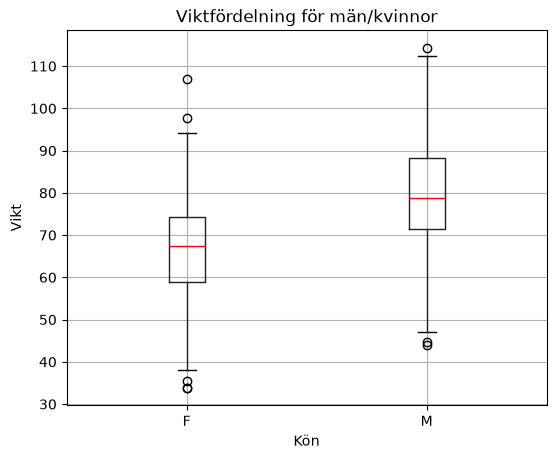

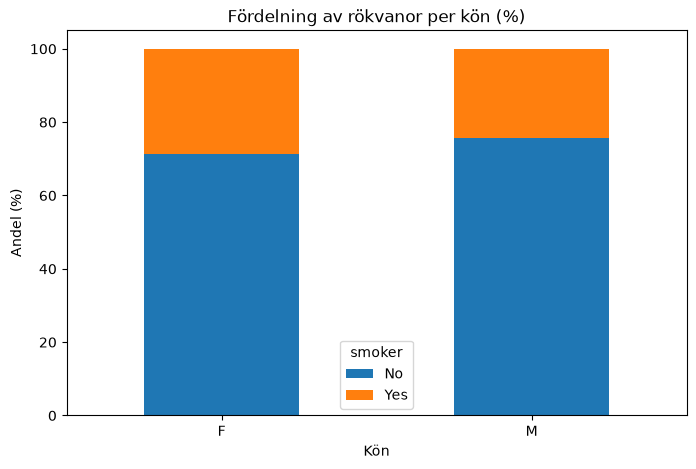

<Figure size 640x480 with 0 Axes>

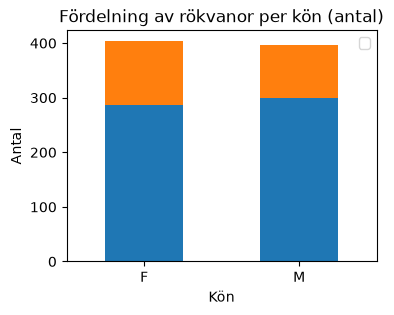

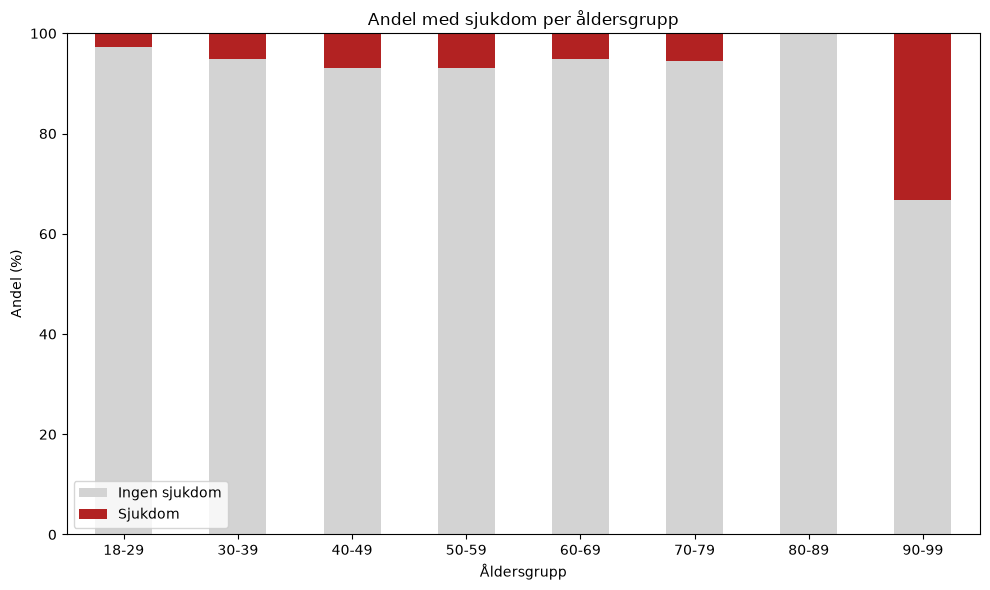

In [22]:
# Histogram + boxplot över systoliskt tryck:

fig, (ax_hist, ax_box) = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={"height_ratios":[4,1]})

ax_hist.hist(df["systolic_bp"], bins=20, edgecolor="black")
ax_hist.set_title("Fördelning av systoliskt tryck")
ax_hist.set_xlabel("Systoliskt tryck")
ax_hist.set_ylabel("Antal")
ax_hist.grid(axis="y")

ax_box.boxplot(df["systolic_bp"], orientation="horizontal")
ax_box.set_yticks([]) 
ax_box.grid(axis="x")

# Boxplot över viktfördelning inom grupperna män/kvinnor:

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="weight", by="sex", medianprops={'color': 'red', 'linewidth': 1}, ax=ax)
ax.set_title("Viktfördelning för män/kvinnor")
ax.set_xlabel("Kön")
ax.set_ylabel("Vikt")
plt.suptitle("")

# Stapeldiagram över rökvanor, uppdelat på män/kvinnor (%):

count_smokers = df.groupby(["sex", "smoker"]).size().unstack()
perc_smokers = count_smokers.div(count_smokers.sum(axis=1), axis=0) * 100

perc_smokers.plot(kind="bar", stacked=True, figsize=(8,5))
plt.xlabel("Kön")
plt.ylabel("Andel (%)")
plt.title("Fördelning av rökvanor per kön (%)")
plt.xticks(rotation=0)
plt.show()

plt.tight_layout()

# Stapeldiagram över antalet rökare fördelat på kön:

count_smokers.plot(kind="bar", stacked=True, figsize=(4, 3))
plt.xlabel("Kön")
plt.ylabel("Antal")
plt.title("Fördelning av rökvanor per kön (antal)")
plt.xticks(rotation=0)
plt.legend([])
plt.show()


# Fördelning av sjuka/icke sjuka baserat på ålder:

# Åldersgruppering
bins = [18, 30, 40, 50, 60, 70, 80, 90, 100]
labels = ["18-29", "30-39", "40-49", "50-59",
          "60-69", "70-79", "80-89", "90-99"]

df["age_group"] = pd.cut(
    df["age"],
    bins=bins,
    labels=labels,
    right=False
)

# Räknar ut antal i varje kombination av åldersgrupp-sjukdom
count = (
    df.groupby(["age_group", "disease"])
      .size()
      .unstack(fill_value=0)
)

# Omvandlar till procent inom varje åldersgrupp
perc = count.div(count.sum(axis=1), axis=0) * 100

perc.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["lightgray", "firebrick"]
)

plt.xlabel("Åldersgrupp")
plt.ylabel("Andel (%)")
plt.title("Andel med sjukdom per åldersgrupp")
plt.xticks(rotation=0)
plt.legend(["Ingen sjukdom", "Sjukdom"], loc="lower left")
plt.tight_layout()
plt.show()


In [23]:
# Jämförelse befintlig data med simulerade personer:

real_dis = df["disease"].mean()

np.random.seed(42)
simu_age = np.random.randint(18, 100, size=1000)
simu_sex = np.random.choice(["M", "F"], size=1000)
simu_height = np.random.normal(loc=170, scale=15, size=1000)
simu_weight = np.random.normal(loc=75, scale=15, size=1000)
simu_bp = np.random.normal(loc=125, scale=15, size=1000)
simu_chol = np.random.normal(loc=5.2, scale=1.0, size=1000)
simu_smoker = np.random.choice(["Yes", "No"], p=[0.25, 0.75], size=1000)
simu_dis = np.random.binomial(n=1, p=real_dis, size=1000)

simu_df = pd.DataFrame({
    "age": simu_age,
    "sex": simu_sex,
    "height": simu_height,
    "weight": simu_weight,
    "systolic_bp": simu_bp,
    "cholesterol": simu_chol,
    "smoker": simu_smoker,
    "disease": simu_dis
})

# simu_df.head(15)

print(f'Prevalens av sjukdom i den verkliga datan: {real_dis:.3f} ({real_dis * 100:.1f}%)')
print(f'Prevalens av sjukdom i den syntetiska datan: {simu_dis.mean():.3f} ({simu_dis.mean() * 100:.1f}%)')

Prevalens av sjukdom i den verkliga datan: 0.059 (5.9%)
Prevalens av sjukdom i den syntetiska datan: 0.046 (4.6%)


- Att det blir en skillnad i sjukdomsprevalensen i grupperna beror sannolikt på slumpvariation. 
- Skillnaden är så pass liten (ca 5% vs ca 6%) att den är förväntad i ett slumpat material. 
- (Och ja, det var onödigt att göra en dataframe med ett helt dataset motsvarande ursprunget, det inser jag i efterhand. Men jag fick träna på det i alla fall.) 

In [24]:
# Konfidensintervall för medelvärdet av systoliskt tryck, med hjälp av Bootstrap:

bp = df["systolic_bp"]

bootstrap_means = []

for _ in range(5000):
    sample = np.random.choice(bp, size=len(bp), replace=True)
    bootstrap_means.append(sample.mean())

ci_boot_low = np.percentile(bootstrap_means, 2.5)
ci_boot_high = np.percentile(bootstrap_means, 97.5)


# Konfidensintervall för medelvärdet av systoliskt tryck, med hjälp av Normalmetoden:

m = bp.mean()
s = bp.std(ddof=1)
se = s / np.sqrt(len(bp))

ci_norm_low = m - 1.96 * se
ci_norm_high = m + 1.96 * se

# Sammanfattande utskrift:

print(f'Medelvärdet för systoliskt tryck: {health_data.loc["systolic_bp", "mean"]:.2f}')
print(f'95% CI (metod: Bootstrap): [{ci_boot_low:.2f}, {ci_boot_high:.2f}]')
print(f'95% CI (metod: Normalapproximation): [{ci_norm_low:.2f}, {ci_norm_high:.2f}]')

Medelvärdet för systoliskt tryck: 149.18
95% CI (metod: Bootstrap): [148.31, 150.07]
95% CI (metod: Normalapproximation): [148.29, 150.07]


- Resultaten av de båda metoderna är mycket lika.
- Likheten är förväntad utifrån att materialet är "medelstort" och ingen uppenbar snedfördelning finns.
- Helhetsbedömningen blir alltså att skattningen troligen är god. 

In [25]:
### Hypotesprövning
# Hypotes: "Rökare har högre medel-blodtryck än icke-rökare"
# Detta är en ensidig hypotesprövning för att undersöka om medelvärdet (gällande blodtryck) för rökare är högre än det för icke-rökare (alternativhypotes).
# Nollhypotes är därmed: "Det är ingen skillnad mellan blodtrycket för rökare och icke-rökare".

bp_smokers = df[df["smoker"] == "Yes"]["systolic_bp"]
bp_nonsmokers = df[df["smoker"] == "No"]["systolic_bp"]

obs_diff = bp_smokers.mean() - bp_nonsmokers.mean()
print(f'Observerad skillnad: {obs_diff:.2f}')

# Bootstrap-test:

boot_diffs = []

for _ in range(5000):
    boot_smokers = np.random.choice(bp_smokers, size=len(bp_smokers), replace=True)
    boot_nonsmokers = np.random.choice(bp_nonsmokers, size=len(bp_nonsmokers), replace=True)
    boot_diffs.append(boot_smokers.mean() - boot_nonsmokers.mean())

boot_diffs = np.array(boot_diffs)

# p-värde:
# Svarar på frågan hur stor andel av bootstrap‑skillnaderna från listan boot_diffs som är lika stora eller större än den observerade skillnaden.

p_value = np.mean(boot_diffs >= obs_diff)
print(f'p-värde (metod: Bootstrap): {p_value:.3f}')


Observerad skillnad: 0.47


p-värde (metod: Bootstrap): 0.505


### Slutsatser av hypotesprövningen 
- p-värdet blir ganska högt vilket innebär att nollhypotesen inte kan förkastas.
- Slumpen ger ofta, i det här materialet, en lika stor eller större skillnad än den vi såg i vårt dataset. 
- Sammanfattningsvis innebär resultatet att i vårt material finns det inte stöd för att hävda att rökare verkligen har högre blodtryck än icke-rökare. 
- Gällande metodval hade vad jag förstår både t-test och Bootstrap-test passat bra eftersom urvalet (800 personer) är ganska stort. 
- Jag valde Bootstrap eftersom metodiken passade ihop med mitt förstahandsval gällande konfidensintervall (även om jag använde båda metoderna där för att träna).

In [ ]:
# Power som en efterhands-analys av hur "stark" bedömningen var. 
# (Till skillnad från en powerberäkning i förväg där beräkningen hjälper till att bedöma hur stora urvalsstorlekar som behövs för en studie.)

# Börjar med att ta fram effektstorleken, dvs Cohen's d:

from statsmodels.stats.power import TTestIndPower

# Observerad skillnad
mean_diff = bp_smokers.mean() - bp_nonsmokers.mean()

# Poolad standardavvikelse
# Ger oss ett mått på spridningen kring medelvärdet för respektive grupps värden.
sd_pooled = np.sqrt((bp_smokers.var(ddof=1) + bp_nonsmokers.var(ddof=1)) / 2)

# Cohen's d
effect_size = mean_diff / sd_pooled

print(f'Skillnad i medelvärde: {mean_diff:.2f}')
print(f'Poolad standardavvikelse: {sd_pooled:.2f}')
print(f'Cohens d: {effect_size:.3f}')

# Med hjälp av effektstorleken kan power beräknas:
analysis = TTestIndPower()

power = analysis.power(
    effect_size=effect_size,
    nobs1=len(bp_smokers),
    ratio=len(bp_nonsmokers) / len(bp_smokers),
    alpha=0.05
)

print(f'Power: {power * 100:.1f}%')

Skillnad i medelvärde: 0.47
Poolad standardavvikelse: 12.95
Cohens d: 0.036
Power: 7.4%


### Min tolkning av poweranalysen:

- Till att börja med ser man att det är en mycket liten skillnad i medelvärde (blodtryck) mellan rökare och icke-rökare i det här materialet.
- Detta kommer i sin tur att innebära att effektstorleken blir väldigt liten (0.036). 
- En så liten effekt är svår att upptäcka från första början och skulle antagligen kräva betydligt större material än vårt för att "synas", om det är en verklig skillnad. 
- Effektstorleken ligger i sin tur till grund för själva powerberäkningen vars resultat därmed blir lågt, bara 7,4%.
- Alltså, om den sanna effekten av rökning på blodtryck är lika liten som den vi såg i det här materialet, så har testet ungefär 7.4% sannolikhet att upptäcka skillnaden (vid alpha = 0.05).
- Jag tog min Copilot till hjälp för att förstå att jag behövde använda TTestIndPower() istället för som i din video där NormalIndPower() används. Eftersom det jag räknar på här handlar om medelvärden gällande kontinuerliga andelar så skiljer sig metoden för det åt jämört med i videon där det gäller proportioner mellan "0 och 1" och således ett binärt utfall.  

In [30]:
required_n = analysis.solve_power(effect_size=effect_size, power=0.80, alpha=0.05)

required_n_rounded = int(np.ceil(required_n))

print(f'Antalet behövda personer per grupp (rökare/icke rökare): {required_n_rounded}')
print(f'Antal rökare i materialet: {len(bp_smokers)}')
print(f'Antal icke-rökare i materialet: {len(bp_nonsmokers)}')

Antalet behövda personer per grupp (rökare/icke rökare): 11825
Antal rökare i materialet: 213
Antal icke-rökare i materialet: 587


### Skattning av antalet behövda personer per grupp
- Det sista kodavsnittet ger en skattning av hur många personer varje grupp skulle behöva innehålla för att ha en chans att upptäcka en faktisk skillnad gällande en så liten medelvärdesskillnad som 0.47 enheter mellan de två grupperna rökare och icke-rökare. 
- Om detta relateras till populationsnivå skulle egentligen bara en stor befolkningsstudie kunna upptäcka en verklig skillnad, givet kanske att förekomsten av rökning skulle vara så hög (typ 25%) som den är i vårt material. 
- I verkligheten klassas Sverige numera som ett rökfritt land (andelen rökare < 5%) och det är därför praktiskt utmanande att få ihop en så stor grupp med rökare idag. 